# Resistive Wall Wake Calculations using PyABS


## Scan over W again to determine TCMI Threshold

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
    
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [3]:
from pyabs.core.basis import ABSBasisConfig, build_abs_basis
from pyabs.core.matrix import build_abs_matrix
from pyabs.core.wake import ThetaWake, WakeScale, ResistiveWallWake
from pyabs.solvers.eigensolvers import solve_eigenvalues, scan_over_w#, solve_system
from pyabs.solvers.systemsolvers import solve_system

In [3]:
n_max=50
basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=0))

In [4]:
wrange = np.linspace(0.0, 3, num=300)

ans = scan_over_w(basis, wrange=wrange, determine_threshold=True, wake_model=ResistiveWallWake(RW=1))
im_wscan = np.array(np.imag(ans.eigenvalues))
re_wscan = np.array(np.real(ans.eigenvalues))
ans.eigenvalues.shape

Modes 0 and -1 couple at wth = 0.45150501672240806


(300, 101)

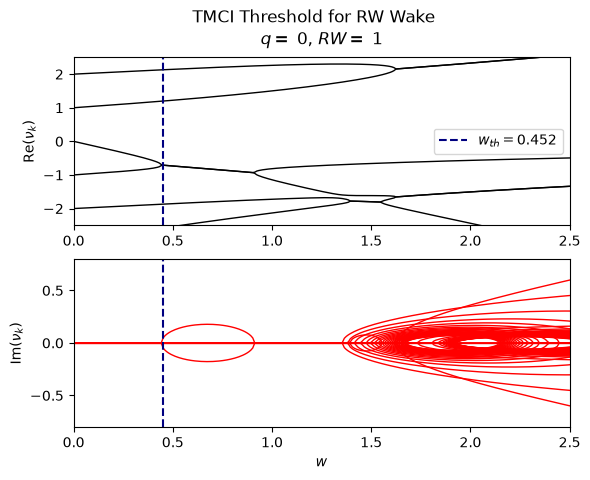

In [5]:
fig, ax = plt.subplots(2)
plt.title(rf"$q = $ 0, $RW =$ 1", y = 2.225)
plt.suptitle(rf"TMCI Threshold for RW Wake")
ax[0].set_ylim(-2.5,2.5)
ax[1].set_ylim(-0.8,0.8)
ax[1].set_xlim(0.0,2.5)
ax[0].set_xlim(0.0,2.5)
ax[1].plot(ans.wake_parameters, im_wscan, color='red', lw=1.0)
ax[0].plot(ans.wake_parameters, re_wscan, color='black', lw=1.0)
ax[0].vlines(ans.threshold, -2.5,2.5, ls = '--', label = rf"$w_{{th}} = {ans.threshold:.03}$", color='navy')
ax[1].vlines(ans.threshold, -0.8,0.8, ls = '--', color='navy')
ax[1].set_ylabel(r"Im($\nu_{k}$)")
ax[0].set_ylabel(r"Re($\nu_{k}$)")
ax[1].set_xlabel(r"$w$")
ax[0].legend()
plt.savefig("../../plots/pyabs_rw.png", dpi=300)
plt.show()

# Test of Stroboscopic Plots and Amplification Factor Calculations

In [118]:
matrix = build_abs_matrix(basis, wake_model=ResistiveWallWake(RW=1.0), scale=WakeScale(w = 1))
solution = solve_system(matrix, A0=1)

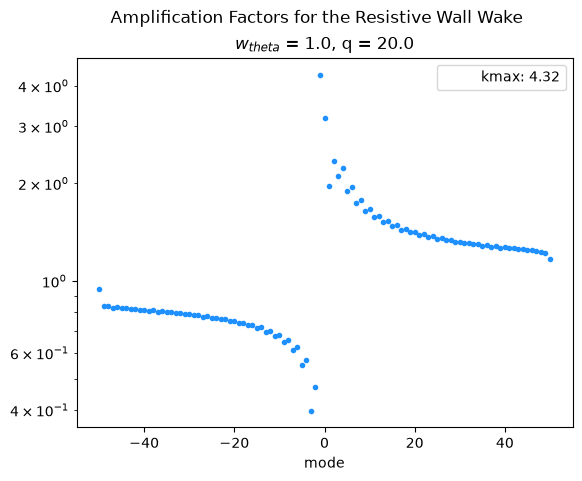

In [119]:
ks, modes = solution.compute_amplification_factors()
kmax = np.max(ks)

fig, ax = plt.subplots()
plt.suptitle(r"Amplification Factors for the Resistive Wall Wake")
plt.title(r"$w_{theta}$ = 1.0, q = 20.0")
plt.scatter(modes, ks, marker='.', color='dodgerblue')
plt.scatter([],[], marker='none',label = f"kmax: {kmax:.2f}")
ax.set_xlabel(r"mode")
#ax.set_ylim(0.8*np.min(ks), kmax+2)
plt.yscale('log')
plt.legend(loc='upper right')
plt.savefig("../../plots/amplification_factors_rw", dpi=300)
plt.show()

In [120]:
from tqdm.notebook import tqdm
strobo_modes = np.arange(-5,7, dtype = int)
psirange=np.linspace(-np.pi, np.pi, 100)
test = []
with tqdm(total=len(psirange), desc="Solving centroid strobes") as pbar:
    for psi in psirange:
        test.append(solution.compute_centroidstrobe(psi=psi, ns = 20))
        pbar.update(1)
    pbar.set_postfix(psi=f"{psi:.2f}")
test = np.array(test)
test.shape

Solving centroid strobes:   0%|          | 0/100 [00:00<?, ?it/s]

(100, 101, 20)

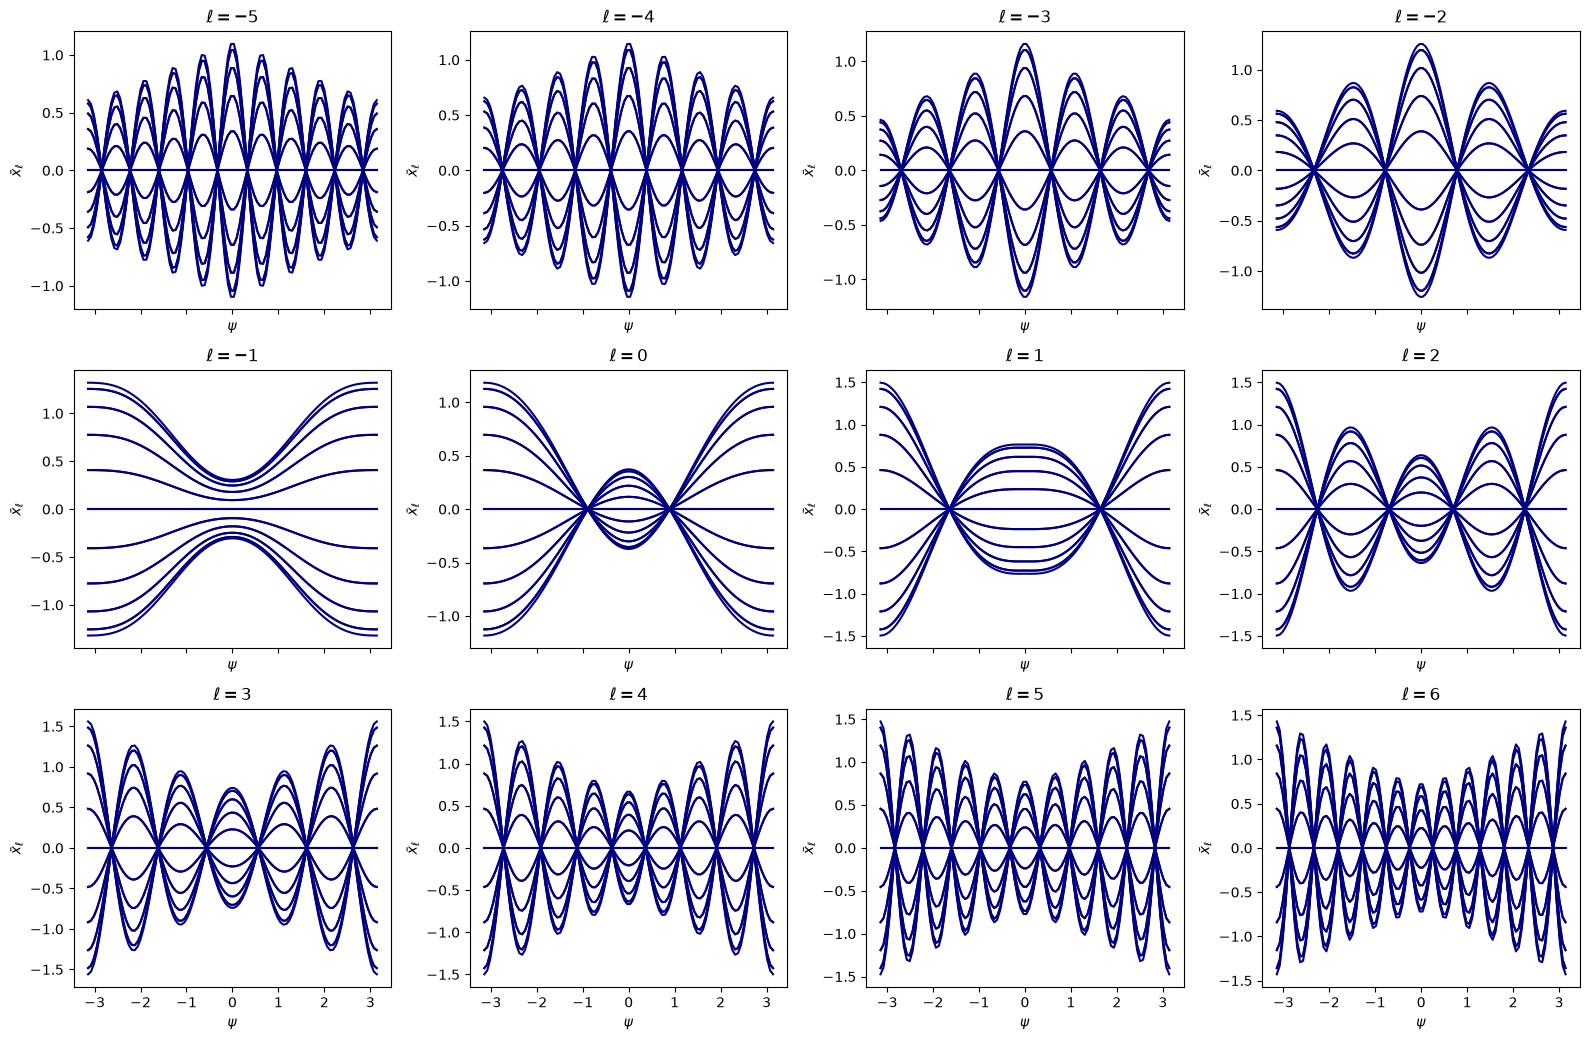

In [121]:
# pick whichever index along the 101 axis you want
#modes = [5]
plot_modes = strobo_modes + n_max
n_size = len(strobo_modes)
ncols = 4
nrows = int(np.ceil(n_size / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), sharex=True, sharey=False)
axes = np.array(axes).reshape(-1)  # flatten in case nrows/ncols > 1
for ax, mode in zip(axes, strobo_modes):
    for k in range(test.shape[2]):
        ydat = test[:, mode+n_max, k]
        ax.plot(psirange, ydat, color='navy')
        #ax.set_ylim(np.min(ydat), np.max(ydat))
    ax.set_title(fr'$\ell = {mode}$')
    #ax.set_ylim(np.min(test[:,mode+n_max,k]), np.max(test[:,mode+n_max,k]))
    ax.set_ylabel(r'$\bar{x}_\ell$')
    ax.set_xlabel(r'$\psi$')

# hide any unused subplot axes if n isn't a perfect multiple of ncols
for ax in axes[n_size:]:
    ax.set_visible(False)

fig.savefig("../../plots/stroboscopic_theta.png", dpi=300)
fig.tight_layout()
plt.show()

In [4]:
%%time
from tqdm.notebook import tqdm
resolution = 300
n_max = 500
n_modes = 2*n_max + 1
qmax = 50
wmax = 100
qrange = np.linspace(0.0, qmax, num=resolution)
wrange = np.linspace(0.0, wmax, num=resolution)
imeig_max = np.empty((resolution, resolution), dtype=float)
log_kmax = np.empty((resolution, resolution), dtype=float)


with tqdm(total=resolution * resolution, desc="Solving eigenvalues") as pbar:
    for i, q in enumerate(qrange):
        basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=q))
        for j, w in enumerate(wrange):
            #wake = ThetaWake(W0=1)
            wake = ResistiveWallWake(RW=1.0)
            matrix = build_abs_matrix(basis, wake_model=wake, scale=WakeScale(w=w))
            solution = solve_system(matrix, A0=1)
            imeig_max[j][i] = np.max(np.array(np.abs(solution.eigenvalues.imag)))
            log_kmax[j][i] = np.log10(np.max(solution.compute_amplification_factors()))
            pbar.update(1)
        pbar.set_postfix(q=f"{q:.1f}")

Solving eigenvalues:   0%|          | 0/90000 [00:00<?, ?it/s]

CPU times: user 47.4 s, sys: 69.3 ms, total: 47.5 s
Wall time: 17.8 s


KeyboardInterrupt: 